# Random Forest — Iris Dataset


## Librerias


In [10]:
# 1. Import all libraries
import pandas as pd
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.preprocessing import MinMaxScaler, label_binarize
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

np.random.seed(123)


## Data


In [11]:
data = pd.DataFrame(datasets.load_iris().data, columns=datasets.load_iris().feature_names)
data['target'] = datasets.load_iris().target
data


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [12]:
data.target.unique()


array([0, 1, 2])

## Data Preparation


In [13]:
n_qubits = 4

X = data.drop(columns='target')
y = data['target']

# Stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=123, stratify=y
)

print(f"Custom Dataset Loaded: Train={len(X_train)}, Test={len(X_test)}")

# Normalize to [0, π]
minmax = MinMaxScaler(feature_range=(0, np.pi))
X_train = minmax.fit_transform(X_train)
X_test = minmax.transform(X_test)
X_test = np.clip(X_test, 0, np.pi)

print(f"Final shapes -> Train: {X_train.shape}, Test: {X_test.shape}")


Custom Dataset Loaded: Train=90, Test=60
Final shapes -> Train: (90, 4), Test: (60, 4)


## Random Forest


In [14]:
class RandomForestModel:
    def __init__(self):
        self.model = RandomForestClassifier(
            n_estimators=100,
            random_state=123,
        )

    def fit(self, X, y):
        self.model.fit(X, y)
        return self

    def predict(self, X):
        return self.model.predict(X)

    def predict_proba(self, X):
        return self.model.predict_proba(X)


## Entrenamiento Random Forest


In [15]:
# Training and timing statistics
print("=== Train Random Forest ===")
rf_model = RandomForestModel()
start = time.time()
rf_model.fit(X_train, y_train)
rf_time = time.time() - start
print(f"Random Forest training time: {rf_time:.2f}s")


=== Train Random Forest ===
Random Forest training time: 0.06s


## Model Evaluation


In [16]:
def evaluate(model, X_t, y_t, classes):
    preds = model.predict(X_t)
    scores = model.predict_proba(X_t)

    acc = accuracy_score(y_t, preds)
    prec = precision_score(y_t, preds, average="macro", zero_division=0)
    rec = recall_score(y_t, preds, average="macro", zero_division=0)
    f1 = f1_score(y_t, preds, average="macro", zero_division=0)
    auc = roc_auc_score(label_binarize(y_t, classes=classes), scores, average="macro")
    return acc, prec, rec, f1, auc, scores, preds


In [17]:
classes = np.unique(y_train)

rf_acc, rf_prec, rf_rec, rf_f1, rf_auc, rf_probs, rf_preds = evaluate(
    rf_model, X_test, y_test, classes
)
rf_acc_tr, rf_prec_tr, rf_rec_tr, rf_f1_tr, rf_auc_tr, _, _ = evaluate(
    rf_model, X_train, y_train, classes
)

print("\n=== Train vs Test ===")
print(
    f"RF Train - Acc: {rf_acc_tr:.4f} | Prec: {rf_prec_tr:.4f} | Rec: {rf_rec_tr:.4f} | "
    f"F1: {rf_f1_tr:.4f} | AUC: {rf_auc_tr:.4f}"
)
print(
    f"RF Test  - Acc: {rf_acc:.4f} | Prec: {rf_prec:.4f} | Rec: {rf_rec:.4f} | "
    f"F1: {rf_f1:.4f} | AUC: {rf_auc:.4f}"
)



=== Train vs Test ===
RF Train - Acc: 1.0000 | Prec: 1.0000 | Rec: 1.0000 | F1: 1.0000 | AUC: 1.0000
RF Test  - Acc: 0.9500 | Prec: 0.9507 | Rec: 0.9500 | F1: 0.9500 | AUC: 0.9910


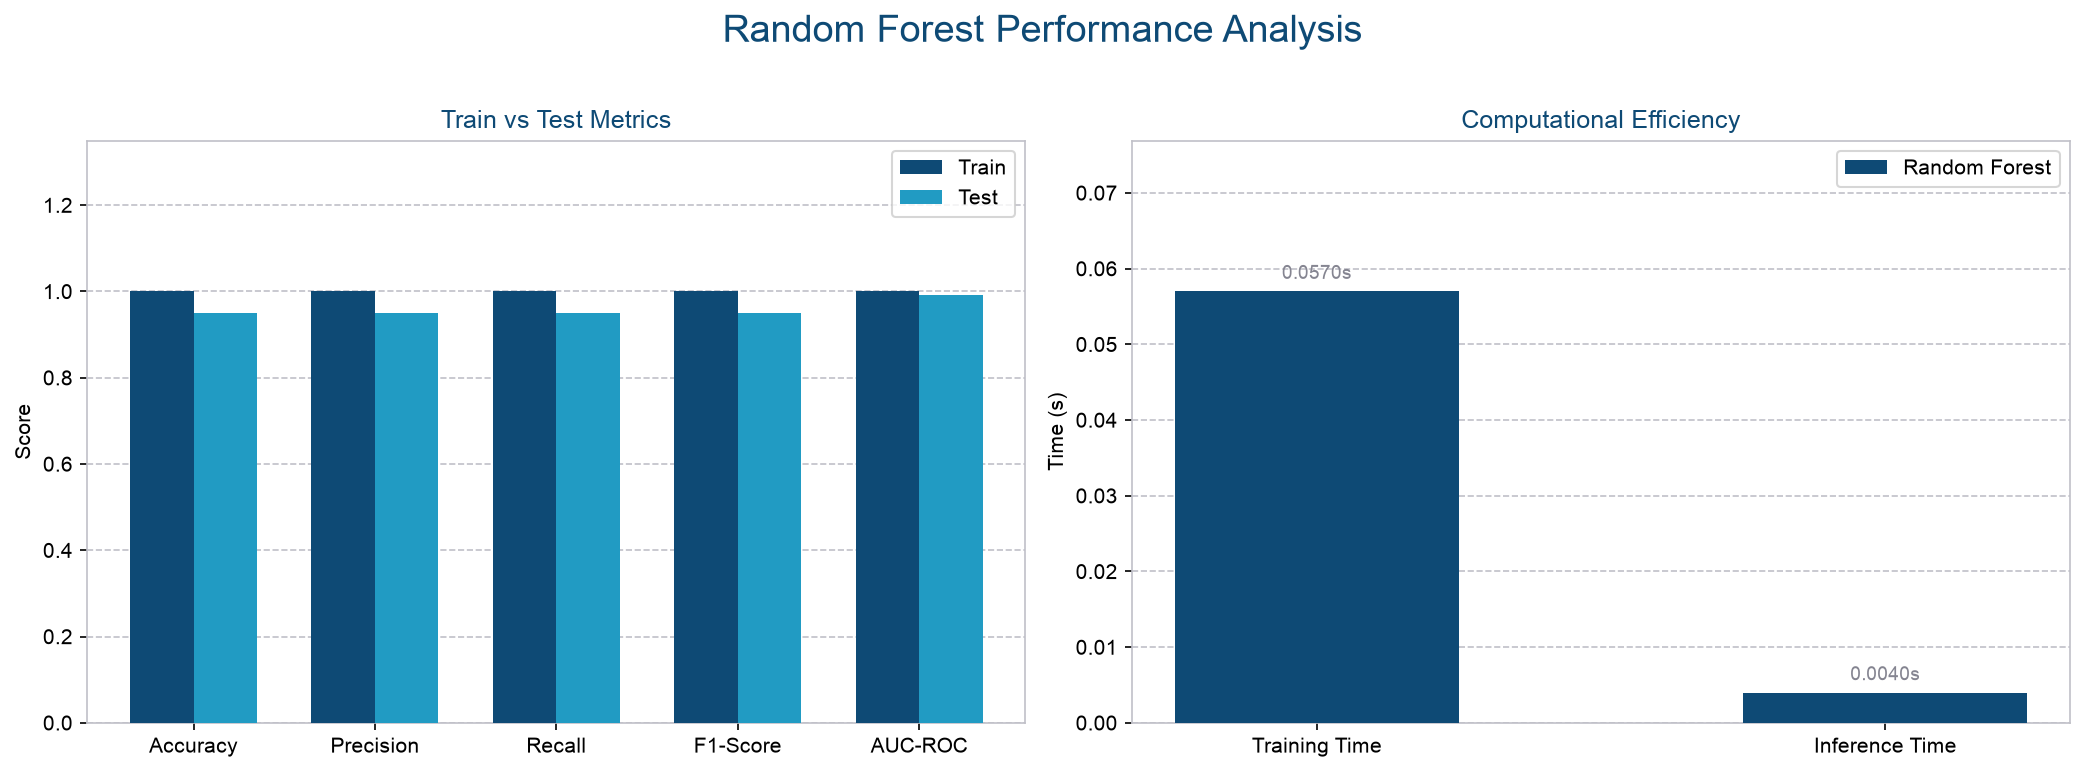

In [18]:
# Result Visualization (train vs test + paleta UNIR)
plt.rcParams.update({
    'font.sans-serif': ['Arial'],
    'axes.edgecolor': '#C0C0C8',
    'grid.color': '#C0C0C8',
    'grid.linestyle': '--'
})

def get_inference_time(model, data):
    start = time.time()
    _ = model.predict(data)
    return time.time() - start

rf_inf_time = get_inference_time(rf_model, X_test)

train_color = '#0E4A75'  # unirnavy
test_color = '#219BC3'   # unirazul
unir_gris = '#858591'

fig, axs = plt.subplots(1, 2, figsize=(14, 5), dpi=150)
fig.suptitle('Random Forest Performance Analysis', fontsize=18, y=1.02, color='#0E4A75')

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
train_vals = [rf_acc_tr, rf_prec_tr, rf_rec_tr, rf_f1_tr, rf_auc_tr]
test_vals = [rf_acc, rf_prec, rf_rec, rf_f1, rf_auc]
x = np.arange(len(metrics))
width = 0.35

for i in range(len(metrics)):
    axs[0].bar(x[i] - width/2, train_vals[i], width, color=train_color,
               label='Train' if i == 0 else '', zorder=3)
    axs[0].bar(x[i] + width/2, test_vals[i], width, color=test_color,
               label='Test' if i == 0 else '', zorder=3)

axs[0].set_ylabel('Score')
axs[0].set_title('Train vs Test Metrics', color='#0E4A75')
axs[0].set_xticks(x)
axs[0].set_xticklabels(metrics)
axs[0].set_ylim(0, 1.35)
axs[0].legend(loc='upper right')
axs[0].grid(axis='y', zorder=0)

eff_labels = ['Training Time', 'Inference Time']
eff = [rf_time, rf_inf_time]
x_eff = np.arange(len(eff_labels))
axs[1].bar(x_eff, eff, 0.5, color=train_color, label='Random Forest', zorder=3)
axs[1].set_xticks(x_eff)
axs[1].set_xticklabels(eff_labels)
axs[1].set_ylabel('Time (s)')
axs[1].set_title('Computational Efficiency', color='#0E4A75')
max_time = max(eff)
axs[1].set_ylim(0, max_time * 1.35 if max_time > 0 else 1)
axs[1].legend(loc='upper right')
axs[1].grid(axis='y', zorder=0)
offset = max_time * 0.02 if max_time > 0 else 0.02
for i in range(2):
    axs[1].text(x_eff[i], eff[i] + offset, f'{eff[i]:.4f}s',
                ha='center', va='bottom', fontsize=9, color=unir_gris)

plt.tight_layout()
plt.show()


## Guardar resultados


In [19]:
# Save metrics for Results notebook
import json
from pathlib import Path

cwd = Path.cwd()
if cwd.name == "Classification":
    metrics_dir = cwd.parent / "Results" / "metrics"
elif (cwd / "Notebooks" / "Results").exists():
    metrics_dir = cwd / "Notebooks" / "Results" / "metrics"
else:
    metrics_dir = cwd / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)

payload = {
    "model": "Random Forest",
    "family": "classical",
    "protocol": {
        "dataset": "iris",
        "test_size": 0.4,
        "random_state": 123,
        "stratify": True,
        "scaler": "MinMaxScaler[0, pi]",
    },
    "train": {
        "accuracy": float(rf_acc_tr),
        "precision": float(rf_prec_tr),
        "recall": float(rf_rec_tr),
        "f1": float(rf_f1_tr),
        "auc": float(rf_auc_tr),
    },
    "test": {
        "accuracy": float(rf_acc),
        "precision": float(rf_prec),
        "recall": float(rf_rec),
        "f1": float(rf_f1),
        "auc": float(rf_auc),
    },
    "train_time_s": float(rf_time),
    "inference_time_s": float(rf_inf_time),
}

out = metrics_dir / "rf_iris.json"
out.write_text(json.dumps(payload, indent=2))
print("Saved:", out)


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Results/metrics/rf.json
